# Practice 1: ML at scaling

## Import modules

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import csv
from itertools import islice
from collections import Counter
import random
from sklearn.decomposition import PCA
from numba import njit, prange 
from numba.typed import List
from numba.types import ListType, Tuple, int64, float64

In [5]:
import os
os.makedirs("/kaggle/working/recomSys", exist_ok=True)

## Load dataset

In [6]:
with open("/kaggle/input/datasets/thaonguyen0712/movielens-32m-dataset/ratings.csv", "r",buffering=4*1024) as file:
    ratings = list(islice(csv.DictReader(file), 32000000))

**Initialization**

In [7]:
user_to_index = dict()
index_to_user = []
item_to_index = dict()
index_to_item = []
data_by_user = []
data_by_item = []

## Double indexing

In [8]:
for row in ratings:
    user = int(row['userId'])
    item = int(row['movieId'])
    rating = float(row['rating'])

    if user not in user_to_index:
        user_to_index[user] = len(index_to_user)
        index_to_user.append(user)
        data_by_user.append([])

    if item not in item_to_index:
        item_to_index[item] = len(index_to_item)
        index_to_item.append(item)
        data_by_item.append([])

    data_by_user[user_to_index[user]].append((item_to_index[item], rating))
    data_by_item[item_to_index[item]].append((user_to_index[user], rating))

In [9]:
print(user_to_index[1])
print(index_to_user[0])

print(item_to_index[1])
print(index_to_item[0])

print(data_by_user[0][:5])
print(data_by_item[0][:5])

0
1
415
17
[(0, 4.0), (1, 1.0), (2, 2.0), (3, 5.0), (4, 5.0)]
[(0, 4.0), (2, 5.0), (14, 4.5), (27, 4.0), (28, 4.0)]


## Exploratory Data Analysis (EDA)

**Statistics**

In [10]:
n_users = len(data_by_user)
n_items = len(data_by_item)

In [11]:
n_ratings = sum(len(u) for u in data_by_user)
density = n_ratings / (n_users * n_items)

print("Users :", n_users)
print("Films        :", n_items)
print("Ratings        :", n_ratings)
print(f"Density      : {density:.4%}")

Users : 200948
Films        : 84432
Ratings        : 32000000
Density      : 0.1886%


**Mean average by user and by film**

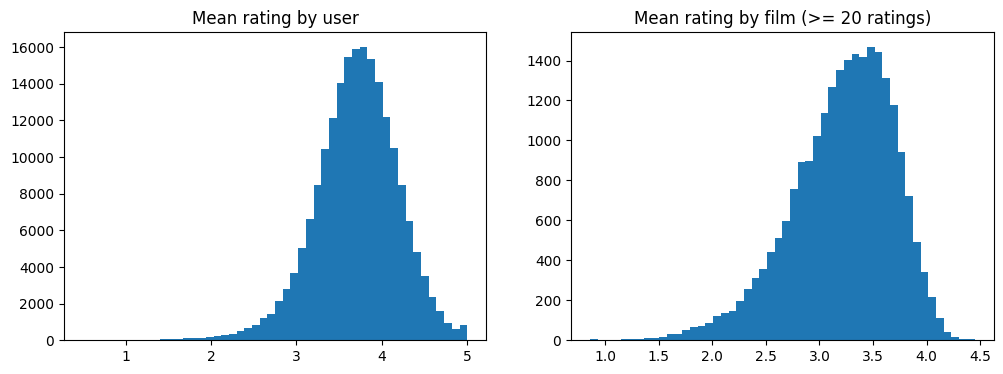

In [12]:
user_counts = [len(u) for u in data_by_user]
item_counts = [len(i) for i in data_by_item]

user_means = [sum(r for _, r in u) / len(u) for u in data_by_user]
item_means = [sum(r for _, r in i) / len(i) for i in data_by_item]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(user_means, bins=50)
ax[0].set_title("Mean rating by user")
ax[1].hist([m for m, c in zip(item_means, item_counts) if c >= 20], bins=50)
ax[1].set_title("Mean rating by film (>= 20 ratings)")
plt.savefig("/kaggle/working/recomSys/mean_rating_by.pdf", bbox_inches="tight")
plt.show()

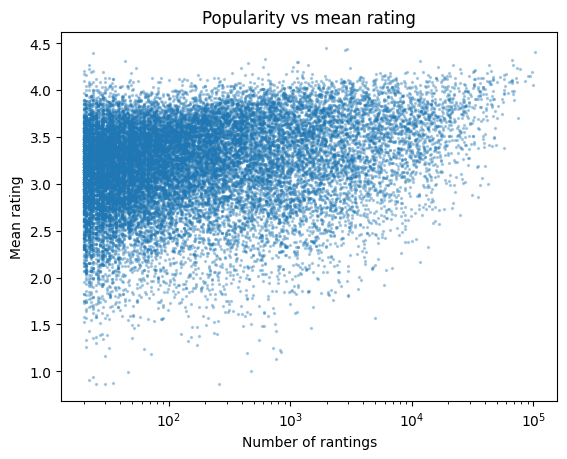

In [13]:
x = [c for c in item_counts if c >= 20]
y = [m for m, c in zip(item_means, item_counts) if c >= 20]
plt.scatter(x, y, s=2, alpha=0.3)
plt.xscale("log")
plt.xlabel("Number of rantings")
plt.ylabel("Mean rating")
plt.title("Popularity vs mean rating")
plt.savefig("/kaggle/working/recomSys/popularity_mean.pdf", bbox_inches="tight")
plt.show()

**Rating Distribution**

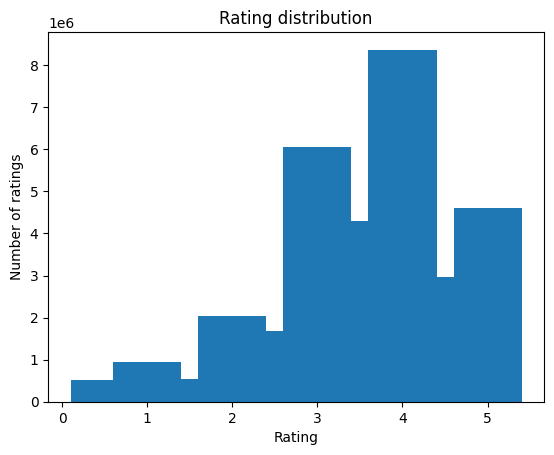

In [14]:
rating_counts = {}

for row in ratings:
    rating = float(row['rating'])
    rating_counts[rating] = rating_counts.get(rating, 0) + 1

x = sorted(rating_counts.keys())
y = [rating_counts[r] for r in x]

plt.bar(x, y)
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.title("Rating distribution")
plt.savefig("/kaggle/working/recomSys/rating_dist.pdf", bbox_inches="tight")
plt.show()

In [12]:
print(rating_counts)

{4.0: 8367618, 1.0: 946664, 2.0: 2028612, 5.0: 4596551, 3.0: 6054970, 3.5: 4290085, 0.5: 525123, 4.5: 2973943, 2.5: 1685374, 1.5: 531060}


**Power-law analysis**

In [15]:
user_degrees = [len(data) for data in data_by_user]
movie_degrees = [len(data) for data in data_by_item]

In [16]:
user_distribution = Counter(user_degrees)
movie_distribution = Counter(movie_degrees)

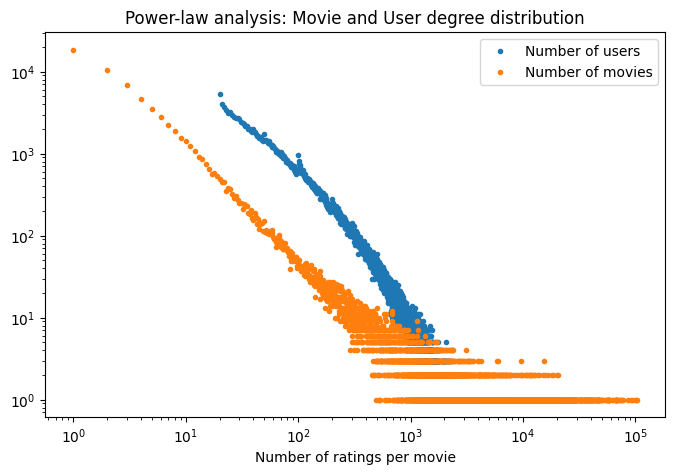

In [17]:
x_user = sorted(user_distribution.keys())
y_user = [user_distribution[k] for k in x_user]

x_movie = sorted(movie_distribution.keys())
y_movie = [movie_distribution[k] for k in x_movie]

plt.figure(figsize=(8, 5))
plt.loglog(x_user, y_user, 'o', markersize=3, label='Number of users')
plt.loglog(x_movie, y_movie, 'o', markersize=3, label='Number of movies')
plt.xlabel("Number of ratings per movie")
plt.title("Power-law analysis: Movie and User degree distribution")
plt.legend()
plt.savefig("/kaggle/working/recomSys/power_low.pdf", bbox_inches="tight")
plt.show()

In [ ]:
n_users = len(data_by_user)
n_items = len(data_by_item)

## Reload the entire dataset

# Practice 2

**Initialization**

In [18]:
user_to_index = dict()
index_to_user = []
item_to_index = dict()
index_to_item = []
data_by_user = []
data_by_item = []

data_by_user_train = []
data_by_item_test = []
data_by_user_test = []
data_by_item_train = []

**Upload and preprocessing**

In [19]:
random.seed(42)

In [20]:
with open("/kaggle/input/datasets/thaonguyen0712/movielens-32m-dataset/ratings.csv", "r") as file:
    ratings = list(islice(csv.DictReader(file), 2000000))
    
    for row in ratings:
        userId = int(row['userId'])
        movieId = int(row['movieId'])
        rating = float(row['rating'])
    
        if userId not in user_to_index:
            user_to_index[userId] = len(user_to_index)
            index_to_user.append(userId)
            data_by_user.append([])
            data_by_user_train.append([])
            data_by_user_test.append([])
        if movieId not in item_to_index:
            item_to_index[movieId] = len(item_to_index)
            index_to_item.append(movieId)
            data_by_item.append([])
            data_by_item_train.append([])
            data_by_item_test.append([])

        m = user_to_index[userId]
        n = item_to_index[movieId]
        data_by_user[m].append([n, rating])
        data_by_item[n].append([m, rating])
        
        if random.random()<0.9:
            data_by_user_train[user_to_index[userId]].append((item_to_index[movieId], rating))
            data_by_item_train[item_to_index[movieId]].append((user_to_index[userId], rating))
        else:
            data_by_user_test[user_to_index[userId]].append((item_to_index[movieId], rating))
            data_by_item_test[item_to_index[movieId]].append((user_to_index[userId], rating))

In [21]:
M = len(user_to_index)
N= len(item_to_index)

In [22]:
train_size = sum([len(u) for u in data_by_user_train])
test_size = sum([len(u) for u in data_by_user_test])

In [23]:
print("Dimensions :", M, "users x", N, "items")
print("Notes train :", train_size)
print("Notes test :", test_size)

Dimensions : 12773 users x 36603 items
Notes train : 1799943
Notes test : 200057


# Modeling

**Computing RMSE**

In [24]:

def rmse_function(data, user_biases, item_biases):
    sum_squared_error = 0
    nb = 0

    for m, user_ratings in enumerate(data):
        for n, r in user_ratings:
            pred = user_biases[m] + item_biases[n]
            sum_squared_error += (r - pred) ** 2
            nb += 1

        rmse = (sum_squared_error / nb) ** 0.5

    return rmse 


**Computing the Negative Log Loss**

In [25]:
def loss_function(data, user_biases, item_biases, lambdaa, gamma):
    sum_squared_error = 0

    for m, user_ratings in enumerate(data):
        for n, r in user_ratings:
            prediction = user_biases[m] + item_biases[n]
            sum_squared_error += (r - prediction) ** 2

    regularization = sum(x**2 for x in user_biases) + sum(x**2 for x in item_biases)

    return 0.5 * lambdaa * sum_squared_error + 0.5 * gamma * regularization

**Initialisation of Hyperparameters**

In [26]:
M = len(data_by_user_train)
N = len(data_by_item_train)

# Initialisation
user_biases = [0.0] * M
item_biases = [0.0] * N

lambdaa = 1.0
gamma = 0.1
iterations = 10

losses = []
rmse_train = []
rmse_test = []

## Alternating Least Squares (ALS)

In [27]:
for iteration in range(iterations):

    # Update user biases
    for m in range(M):
        bias = 0
        item_counter = 0

        for n, r in data_by_user[m]:
            bias += lambdaa * (r - item_biases[n])
            item_counter += 1

        user_biases[m] = bias / (lambdaa * item_counter + gamma)

    # Update movie biases
    for n in range(N):
        bias = 0
        user_counter = 0

        for m, r in data_by_item[n]:
            bias += lambdaa * (r - user_biases[m])
            user_counter += 1

        item_biases[n] = bias / (lambdaa * user_counter + gamma)

    # Evaluate after each iteration
    losses.append(
        loss_function(data_by_user, user_biases, item_biases, lambdaa, gamma)
    )

    rmse_train.append(
        rmse_function(data_by_user_train, user_biases, item_biases)
    )

    rmse_test.append(
        rmse_function(data_by_user_test, user_biases, item_biases)
    )

    print(
        f"Epoch {iteration + 1}: "
        f"Loss = {losses[iteration]:.4f}, "
        f"RMSE_train = {rmse_train[iteration]:.4f}, "
        f"RMSE_test = {rmse_test[iteration]:.4f}"
    ) 

Epoch 1: Loss = 744257.9377, RMSE_train = 0.8570, RMSE_test = 0.8566
Epoch 2: Loss = 718728.4676, RMSE_train = 0.8421, RMSE_test = 0.8411
Epoch 3: Loss = 717210.8381, RMSE_train = 0.8412, RMSE_test = 0.8401
Epoch 4: Loss = 717075.9540, RMSE_train = 0.8411, RMSE_test = 0.8400
Epoch 5: Loss = 717047.2691, RMSE_train = 0.8411, RMSE_test = 0.8400
Epoch 6: Loss = 717029.5070, RMSE_train = 0.8411, RMSE_test = 0.8400
Epoch 7: Loss = 717013.3637, RMSE_train = 0.8411, RMSE_test = 0.8400
Epoch 8: Loss = 716997.5821, RMSE_train = 0.8411, RMSE_test = 0.8400
Epoch 9: Loss = 716981.9368, RMSE_train = 0.8411, RMSE_test = 0.8400
Epoch 10: Loss = 716966.3797, RMSE_train = 0.8411, RMSE_test = 0.8400


In [28]:
print("M =", M)
print("N =", N)
print("user_biases =", len(user_biases))
print("item_biases =", len(item_biases))

M = 12773
N = 36603
user_biases = 12773
item_biases = 36603


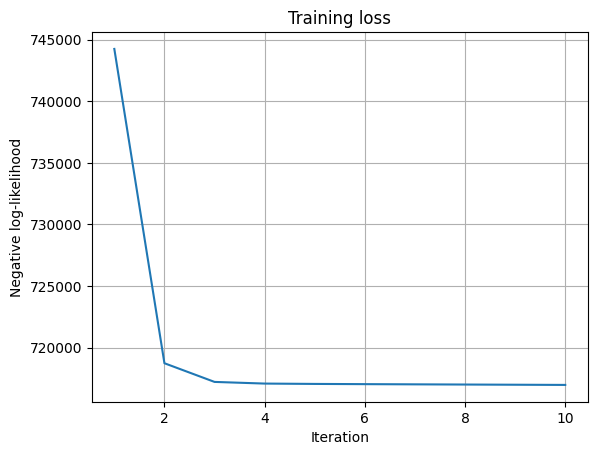

In [29]:
# Plot loss
plt.plot(range(1, iterations + 1), losses)
plt.xlabel("Iteration")
plt.ylabel("Negative log-likelihood")
plt.title("Training loss")
plt.grid(True)
plt.savefig("/kaggle/working/recomSys/prac_2_loss.pdf", bbox_inches="tight")
plt.show()

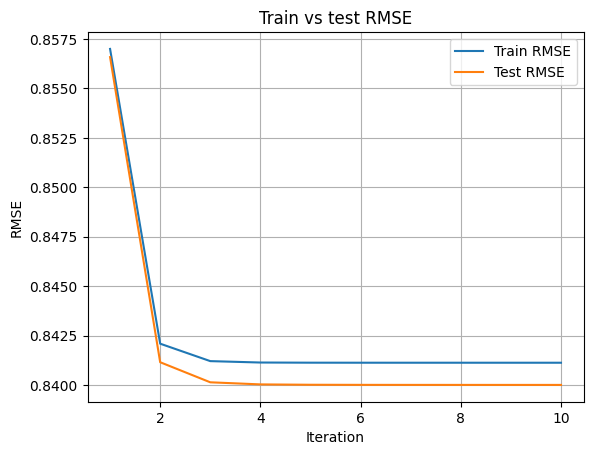

Final train RMSE: 0.841124218218254
Final test RMSE: 0.8400017865970191


In [30]:
# Plot RMSE
plt.plot(range(1, iterations + 1), rmse_train, label="Train RMSE")
plt.plot(range(1, iterations + 1), rmse_test, label="Test RMSE")
plt.xlabel("Iteration")
plt.ylabel("RMSE")
plt.title("Train vs test RMSE")
plt.legend()
plt.grid(True)
plt.savefig("/kaggle/working/recomSys/pract_2_rmse.pdf", bbox_inches="tight")
plt.show()

print("Final train RMSE:", rmse_train[-1])
print("Final test RMSE:", rmse_test[-1])

### Discussion:
***The negative log-likelihood decreases monotonically, as expected since each ALS step exactly minimises the loss over one block of parameters. The training RMSE converges to about 0.841, and the test RMSE converges to about 0.840. The test error follows the training error closely, with the same fast drop in the first 2-3 iterations and then a plateau. The test RMSE is even slightly lower than the training RMSE, which is possible here because the model has very few parameters (one bias per user and per item) compared with the number of ratings, so the gap between train and test is essentially noise from the split.***

# Practical 3

**Initialization**

In [31]:
# Parameters
K = 10
lambdaa = 1.0
gamma = 0.1
iterations = 30

M = len(user_to_index)
N = len(item_to_index)

In [32]:
# Initialization
user_biases = np.zeros(M)
item_biases = np.zeros(N)

U = np.random.normal(0, 0.1, (M, K))
V = np.random.normal(0, 0.1, (N, K))

losses = []
rmse_train = []
rmse_test = []

In [34]:
user_to_index = dict()
index_to_user = []
item_to_index = dict()
index_to_item = []

data_by_user_train = []
data_by_item_test = []
data_by_user_test = []
data_by_item_train = []

**Load and Split**

In [35]:
with open("/kaggle/input/datasets/thaonguyen0712/movielens-32m-dataset/ratings.csv", "r") as file:
    ratings = list(islice(csv.DictReader(file), 2000000))
    
    for row in ratings:
        userId = int(row['userId'])
        movieId = int(row['movieId'])
        rating = float(row['rating'])
    
        if userId not in user_to_index:
            user_to_index[userId] = len(user_to_index)
            index_to_user.append(userId)
            data_by_user_train.append([])
            data_by_user_test.append([])
            
        if movieId not in item_to_index:
            item_to_index[movieId] = len(item_to_index)
            index_to_item.append(movieId)
            data_by_item_train.append([])
            data_by_item_test.append([])
            
        if random.random()<0.9:
            data_by_user_train[user_to_index[userId]].append([item_to_index[movieId], rating])
            data_by_item_train[item_to_index[movieId]].append([user_to_index[userId], rating])
        else:
            data_by_user_test[user_to_index[userId]].append([item_to_index[movieId], rating])
            data_by_item_test[item_to_index[movieId]].append([user_to_index[userId], rating])

**Compute functions loss function**

In [36]:
def loss_function(data_by_user, user_biases, item_biases, U, V, lambdaa, gamma):
    squared_error = 0

    for m, user_ratings in enumerate(data_by_user):
        for n, r in user_ratings:
            prediction = user_biases[m] + item_biases[n] + np.dot(U[m], V[n])
            squared_error += (r - prediction) ** 2

    regularization = (
        lambdaa * (np.sum(user_biases**2) + np.sum(item_biases**2))
        + gamma * (np.sum(U**2) + np.sum(V**2))
    )

    return 0.5 * (squared_error + regularization)

**Compute RMSE funtions**

In [37]:
def rmse_function(data_by_user, user_biases, item_biases, U, V):
    squared_error = 0
    count = 0

    for m, user_ratings in enumerate(data_by_user):
        for n, r in user_ratings:
            prediction = user_biases[m] + item_biases[n] + np.dot(U[m], V[n])
            squared_error += (r - prediction) ** 2
            count += 1

    return np.sqrt(squared_error / count)

**Compute evaluation function**

In [38]:
def evaluation_function(data_by_user_train, data_by_user_test,
                        user_biases, item_biases, U, V):

    train_rmse = rmse_function(data_by_user_train, user_biases, item_biases, U, V)

    test_rmse = rmse_function(data_by_user_test, user_biases, item_biases, U, V)

    return train_rmse, test_rmse

## Training ALS Algorithm with embeddings 

In [ ]:
for iteration in range(iterations):

    # Update user biases
    for m in range(M):
        bias = 0
        counter = 0

        for n, r in data_by_user_train[m]:
            prediction = item_biases[n] + np.dot(U[m], V[n])
            bias += r - prediction
            counter += 1

        user_biases[m] = bias / (counter + lambdaa)

    # Update user vectors
    identity = np.eye(K)

    for m in range(M):
        A = gamma * identity
        B = np.zeros(K)

        for n, r in data_by_user_train[m]:
            A += np.outer(V[n], V[n])
            B += V[n] * (r - user_biases[m] - item_biases[n])

        U[m] = np.linalg.solve(A, B)

    # Update item biases
    for n in range(N):
        bias = 0
        counter = 0

        for m, r in data_by_item_train[n]:
            prediction = user_biases[m] + np.dot(U[m], V[n])
            bias += r - prediction
            counter += 1

        item_biases[n] = bias / (counter + lambdaa)

    # Update item vectors
    for n in range(N):
        A = gamma * identity
        B = np.zeros(K)

        for m, r in data_by_item_train[n]:
            A += np.outer(U[m], U[m])
            B += U[m] * (r - user_biases[m] - item_biases[n])

        V[n] = np.linalg.solve(A, B)

    # Training loss
    loss = loss_function(
        data_by_user, user_biases, item_biases,
        U, V, lambdaa, gamma
    )
    losses.append(loss)

    # Evaluation
    train_rmse, test_rmse = evaluation_function(
        data_by_user_train, data_by_user_test,
        user_biases, item_biases, U, V
    )

    rmse_train.append(train_rmse)
    rmse_test.append(test_rmse)

    print(
        f"Epoch {iteration + 1}: "
        f"Loss = {loss:.2f}, "
        f"Train RMSE = {train_rmse:.4f}, "
        f"Test RMSE = {test_rmse:.4f}"
    ) 

Epoch 1: Loss = 747083.33, Train RMSE = 0.7859, Test RMSE = 0.9528
Epoch 2: Loss = 671224.13, Train RMSE = 0.7365, Test RMSE = 0.9398
Epoch 3: Loss = 632901.47, Train RMSE = 0.7123, Test RMSE = 0.9264
Epoch 4: Loss = 609314.91, Train RMSE = 0.6978, Test RMSE = 0.9163
Epoch 5: Loss = 594164.06, Train RMSE = 0.6887, Test RMSE = 0.9107
Epoch 6: Loss = 583710.70, Train RMSE = 0.6827, Test RMSE = 0.9074
Epoch 7: Loss = 576039.93, Train RMSE = 0.6783, Test RMSE = 0.9055
Epoch 8: Loss = 570137.79, Train RMSE = 0.6751, Test RMSE = 0.9046
Epoch 9: Loss = 565374.46, Train RMSE = 0.6727, Test RMSE = 0.9040
Epoch 10: Loss = 561385.31, Train RMSE = 0.6708, Test RMSE = 0.9035
Epoch 11: Loss = 557955.55, Train RMSE = 0.6692, Test RMSE = 0.9030
Epoch 12: Loss = 554938.47, Train RMSE = 0.6679, Test RMSE = 0.9025
Epoch 13: Loss = 552250.87, Train RMSE = 0.6669, Test RMSE = 0.9020
Epoch 14: Loss = 549830.43, Train RMSE = 0.6660, Test RMSE = 0.9015
Epoch 15: Loss = 547631.07, Train RMSE = 0.6652, Test RMS

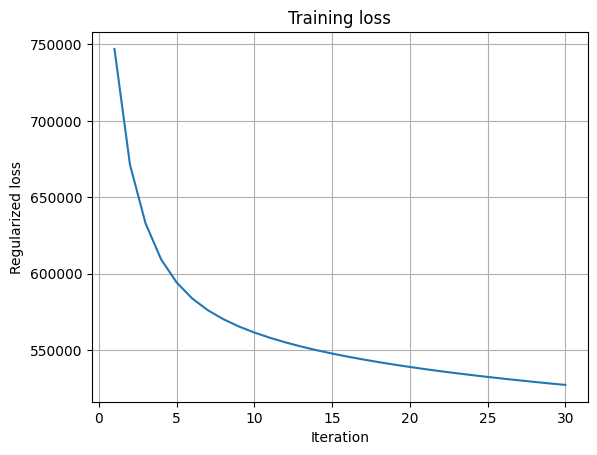

In [40]:
# Plot loss
plt.plot(range(1, len(losses) + 1), losses)
plt.xlabel("Iteration")
plt.ylabel("Regularized loss")
plt.title("Training loss")
plt.grid(True)
plt.savefig("/kaggle/working/recomSys/pract_3_loss.pdf", bbox_inches="tight")
plt.show()

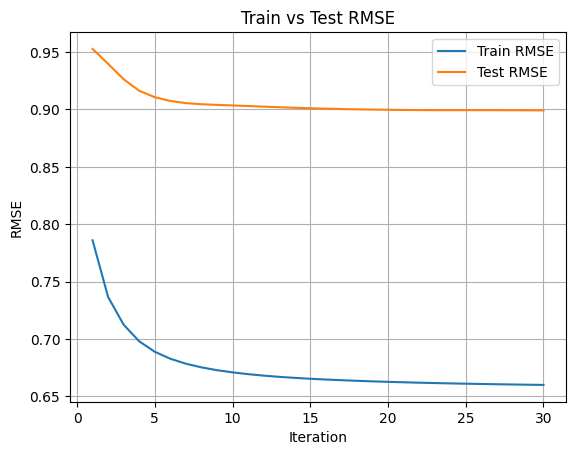

Final train RMSE: 0.6598287801297199
Final test RMSE: 0.8992138392588376


In [41]:
# Plot RMSE
plt.plot(range(1, iterations + 1), rmse_train, label="Train RMSE")
plt.plot(range(1, iterations + 1), rmse_test, label="Test RMSE")
plt.xlabel("Iteration")
plt.ylabel("RMSE")
plt.title("Train vs Test RMSE")
plt.legend()
plt.grid(True)
plt.savefig("/kaggle/working/recomSys/pract_3_rmse.pdf", bbox_inches="tight")
plt.show()

print("Final train RMSE:", rmse_train[-1])
print("Final test RMSE:", rmse_test[-1])


In [ ]:
# check tqdm, from tqdm.notebook

### 2D Projection of User and Item Latent Vectors using PCA

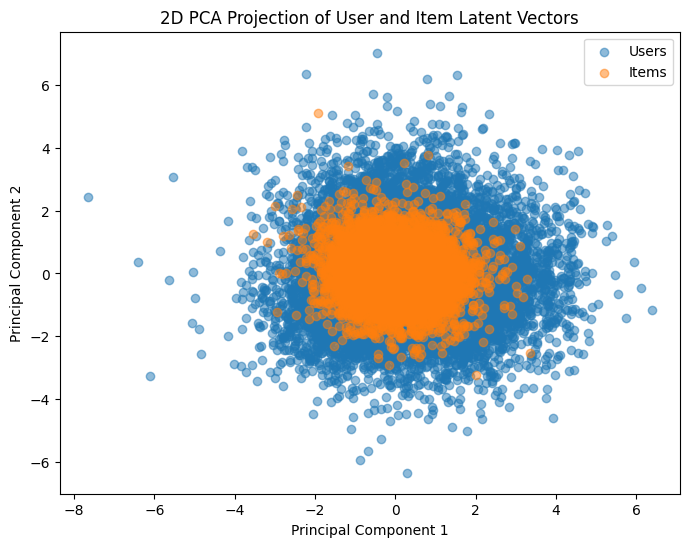

In [42]:
# latent vectors
U_latent = PCA(n_components=2).fit_transform(U)
V_latent = PCA(n_components=2).fit_transform(V)

# Viz
plt.figure(figsize=(8, 6))
plt.scatter(U_latent[:, 0], U_latent[:, 1], alpha=0.5, label="Users")
plt.scatter(V_latent[:, 0], V_latent[:, 1], alpha=0.5, label="Items")

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("2D PCA Projection of User and Item Latent Vectors")
plt.legend()
plt.savefig("/kaggle/working/recomSys/pract_3_PCA.pdf", bbox_inches="tight")
plt.show()

# Practical 4

**Initialization**

In [44]:
user_to_index = dict()
index_to_user = []
item_to_index = dict()
index_to_item = []

data_by_user_train = []
data_by_item_test = []
data_by_user_test = []
data_by_item_train = []

In [45]:
# Parameters
K = 10
lambdaa = 1.0
gamma = 0.1
iterations = 10

M = len(user_to_index)
N = len(item_to_index)

In [46]:
random.seed(42)

**Load and Split**

In [47]:
with open("/kaggle/input/datasets/thaonguyen0712/movielens-32m-dataset/ratings.csv", "r", buffering=4*1024) as file:
    ratings = list(islice(csv.DictReader(file), 32000000))
    
    for row in ratings:
        userId = int(row['userId'])
        movieId = int(row['movieId'])
        rating = float(row['rating'])
    
        if userId not in user_to_index:
            user_to_index[userId] = len(user_to_index)
            index_to_user.append(userId)
            data_by_user_train.append([])
            data_by_user_test.append([])
        if movieId not in item_to_index:
            item_to_index[movieId] = len(item_to_index)
            index_to_item.append(movieId)
            data_by_item_train.append([])
            data_by_item_test.append([])

        
        if random.random()<0.9:
            data_by_user_train[user_to_index[userId]].append([item_to_index[movieId], rating])
            data_by_item_train[item_to_index[movieId]].append([user_to_index[userId], rating])
        else:
            data_by_user_test[user_to_index[userId]].append([item_to_index[movieId], rating])
            data_by_item_test[item_to_index[movieId]].append([user_to_index[userId], rating])

In [56]:
M = len(user_to_index)
N= len(item_to_index)

## Adapting data structure to Numba for acceleration and parellelization

In [57]:
pair_type = Tuple((int64, float64))
row_type = ListType(pair_type)


def prepare_data(data):
    result = List.empty_list(row_type)

    for row in data:
        new_row = List.empty_list(pair_type)

        for index, rating in row:
            new_row.append((int(index), float(rating)))

        result.append(new_row)

    return result


user_train = prepare_data(data_by_user_train)
item_train = prepare_data(data_by_item_train)
user_test = prepare_data(data_by_user_test)

## Parallelizattion

### Update functions

In [59]:
@njit(parallel=True)
def update_user_biases(data_by_user_train, user_biases,
                       item_biases, U, V, lambdaa):
    for m in prange(len(data_by_user_train)):
        bias = 0.0
        counter = len(data_by_user_train[m])

        for n, r in data_by_user_train[m]:
            prediction = item_biases[n] + np.dot(U[m], V[n])
            bias += r - prediction

        user_biases[m] = bias / (counter + lambdaa)


@njit(parallel=True)
def update_user_vectors(data_by_user_train, user_biases,
                        item_biases, U, V, K, gamma):
    identity = np.eye(K)

    for m in prange(len(data_by_user_train)):
        A = gamma * identity.copy()
        B = np.zeros(K)

        for n, r in data_by_user_train[m]:
            A += np.outer(V[n], V[n])
            B += V[n] * (r - user_biases[m] - item_biases[n])

        U[m] = np.linalg.solve(A, B)


@njit(parallel=True)
def update_item_biases(data_by_item_train, user_biases,
                       item_biases, U, V, lambdaa):
    for n in prange(len(data_by_item_train)):
        bias = 0.0
        counter = len(data_by_item_train[n])

        for m, r in data_by_item_train[n]:
            prediction = user_biases[m] + np.dot(U[m], V[n])
            bias += r - prediction

        item_biases[n] = bias / (counter + lambdaa)


@njit(parallel=True)
def update_item_vectors(data_by_item_train, user_biases,
                        item_biases, U, V, K, gamma):
    identity = np.eye(K)

    for n in prange(len(data_by_item_train)):
        A = gamma * identity.copy()
        B = np.zeros(K)

        for m, r in data_by_item_train[n]:
            A += np.outer(U[m], U[m])
            B += U[m] * (r - user_biases[m] - item_biases[n])

        V[n] = np.linalg.solve(A, B)

### Computing loss and RMSE functions

**Loss**

In [60]:
@njit(parallel=True)
def loss_function(data_by_user, user_biases, item_biases,
                  U, V, lambdaa, gamma):
    loss = 0.0

    for m in prange(len(data_by_user)):
        for n, r in data_by_user[m]:
            prediction = user_biases[m] + item_biases[n] + np.dot(U[m], V[n])
            loss += (r - prediction) ** 2

    loss += lambdaa * (np.sum(user_biases ** 2) + np.sum(item_biases ** 2))
    loss += gamma * (np.sum(U ** 2) + np.sum(V ** 2))

    return 0.5 * loss

**RMSE**

In [61]:
@njit(parallel=True)
def rmse_function(data_by_user, user_biases, item_biases, U, V):
    squared_error = 0.0
    counter = 0

    for m in prange(len(data_by_user)):
        for n, r in data_by_user[m]:
            prediction = user_biases[m] + item_biases[n] + np.dot(U[m], V[n])
            squared_error += (r - prediction) ** 2
            counter += 1

    return np.sqrt(squared_error / counter)

## Computing ALS Algorithm

In [62]:
def als_train(data_by_user_train, data_by_item_train,
              data_by_user_test, K, lambdaa, gamma,
              iterations, seed=42):

    M = len(data_by_user_train)
    N = len(data_by_item_train)

    rng = np.random.default_rng(seed)

    user_biases = np.zeros(M)
    item_biases = np.zeros(N)
    U = rng.normal(0, 0.1, (M, K))
    V = rng.normal(0, 0.1, (N, K))

    losses = []
    rmse_train = []
    rmse_test = []

    for iteration in range(iterations):
        update_user_biases(
            data_by_user_train, user_biases, item_biases, U, V, lambdaa
        )
        update_user_vectors(
            data_by_user_train, user_biases, item_biases, U, V, K, gamma
        )
        update_item_biases(
            data_by_item_train, user_biases, item_biases, U, V, lambdaa
        )
        update_item_vectors(
            data_by_item_train, user_biases, item_biases, U, V, K, gamma
        )

        loss = loss_function(
            data_by_user_train, user_biases, item_biases,
            U, V, lambdaa, gamma
        )

        train_error = rmse_function(
            data_by_user_train, user_biases, item_biases, U, V
        )
        test_error = rmse_function(
            data_by_user_test, user_biases, item_biases, U, V
        )

        losses.append(loss)
        rmse_train.append(train_error)
        rmse_test.append(test_error)

        print(
            f"Epoch {iteration + 1}: Loss={loss:.2f}, "
            f"Train RMSE={train_error:.4f}, "
            f"Test RMSE={test_error:.4f}"
        )

    return (
        user_biases, item_biases, U, V,
        losses, rmse_train, rmse_test
    )

**Comparing K10 $ K20**

In [ ]:
lambdaa = 0.1
gamma = 0.1
iterations = 10

results = {}

for K in [10, 20]:
    results[K] = als_train(
        user_train,
        item_train,
        user_test,
        K=K,
        lambdaa=lambdaa,
        gamma=gamma,
        iterations=iterations
    )

/tmp/ipykernel_48/1224358454.py:6: NumbaTypeSafetyWarning: unsafe cast from uint64 to int64. Precision may be lost.
  counter = len(data_by_user_train[m])


Epoch 1: Loss=9983069.12, Train RMSE=0.8217, Test RMSE=0.9021
Epoch 2: Loss=8826266.25, Train RMSE=0.7713, Test RMSE=0.8619
Epoch 3: Loss=8169779.45, Train RMSE=0.7414, Test RMSE=0.8337
Epoch 4: Loss=7833748.66, Train RMSE=0.7257, Test RMSE=0.8186
Epoch 5: Loss=7651592.34, Train RMSE=0.7171, Test RMSE=0.8101
Epoch 6: Loss=7542722.62, Train RMSE=0.7121, Test RMSE=0.8049
Epoch 7: Loss=7472178.04, Train RMSE=0.7088, Test RMSE=0.8015
Epoch 8: Loss=7423470.11, Train RMSE=0.7066, Test RMSE=0.7993
Epoch 9: Loss=7388169.02, Train RMSE=0.7051, Test RMSE=0.7978
Epoch 10: Loss=7361575.16, Train RMSE=0.7039, Test RMSE=0.7967
Epoch 1: Loss=9318101.18, Train RMSE=0.7886, Test RMSE=0.9353
Epoch 2: Loss=7993264.63, Train RMSE=0.7287, Test RMSE=0.8907
Epoch 3: Loss=7327233.33, Train RMSE=0.6969, Test RMSE=0.8616


In [96]:
for K in [10, 20]:
    print(
        f"K={K}: "
        f"Train RMSE={results[K][5][-1]:.4f}, "
        f"Test RMSE={results[K][6][-1]:.4f}"
    )

K=10: Train RMSE=0.7039, Test RMSE=0.7967
K=20: Train RMSE=0.6511, Test RMSE=0.8232


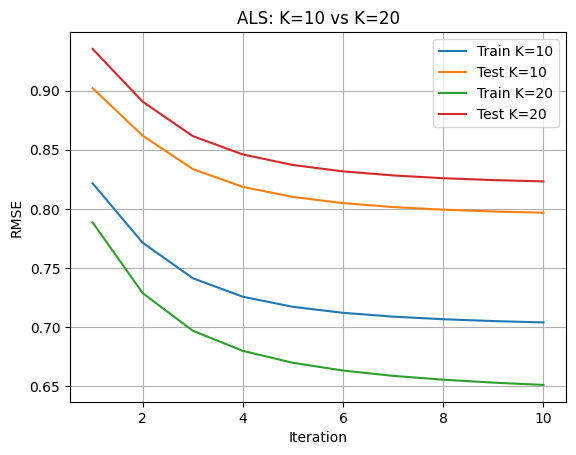

In [85]:
for K in [10, 20]:
    train_history = results[K][5]
    test_history = results[K][6]

    plt.plot(range(1, iterations + 1), train_history, label=f"Train K={K}")
    plt.plot(range(1, iterations + 1), test_history, label=f"Test K={K}")

plt.xlabel("Iteration")
plt.ylabel("RMSE")
plt.title("ALS: K=10 vs K=20")
plt.legend()
plt.grid()
plt.savefig("/kaggle/working/recomSys/pract_4_rmse_k10_k20_rmse).pdf", bbox_inches="tight")
plt.show()

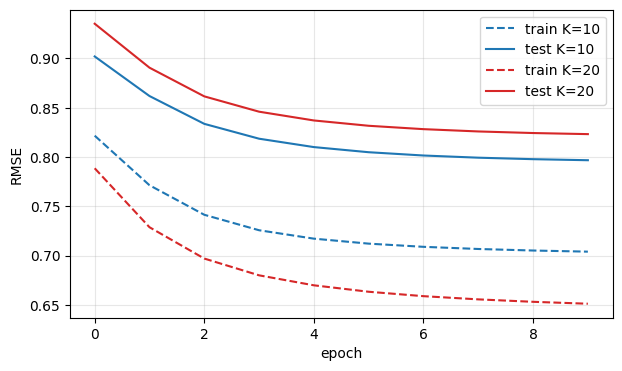

In [97]:
plt.figure(figsize=(7, 4))
for K, color in [(10, "tab:blue"), (20, "tab:red")]:
    _, _, _, _, losses, rmse_train, rmse_test = results[K]
    plt.plot(rmse_train, "--", color=color, label=f"train K={K}")
    plt.plot(rmse_test, "-", color=color, label=f"test K={K}")
plt.xlabel("epoch")
plt.ylabel("RMSE")
plt.title("ALS: K=10 vs K=20")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("/kaggle/working/recomSys/pract_4_rmse_k10_k20_rmse).pdf", bbox_inches="tight")
plt.show()

In [101]:
@njit(parallel=True)
def squared_error_per_user(data_by_user, user_biases, item_biases, U, V):
    """Somme des erreurs au carré de chaque utilisateur (pour l'analyse par utilisateur)."""
    result = np.zeros(len(data_by_user))

    for m in prange(len(data_by_user)):
        s = 0.0
        for n, r in data_by_user[m]:
            prediction = user_biases[m] + item_biases[n] + np.dot(U[m], V[n])
            s += (r - prediction) ** 2
        result[m] = s

    return result


@njit(parallel=True)
def item_statistics(data_by_item):
    """Nombre de ratings et note moyenne de chaque film."""
    count = np.zeros(len(data_by_item))
    mean = np.zeros(len(data_by_item))

    for n in prange(len(data_by_item)):
        s = 0.0
        for m, r in data_by_item[n]:
            s += r
        count[n] = len(data_by_item[n])
        if count[n] > 0:
            mean[n] = s / count[n]

    return count, mean

In [103]:
import pandas as pd

In [104]:
n_train_per_user = np.array([len(row) for row in data_by_user_train])
n_test_per_user = np.array([len(row) for row in data_by_user_test])

bins = [0, 30, 50, 100, 200, 500, 1000, 10**7]
group = np.digitize(n_train_per_user, bins) - 1

rows = []
for K in [10, 20]:
    user_biases, item_biases, U, V = results[K][:4]
    se_train = squared_error_per_user(user_train, user_biases, item_biases, U, V)
    se_test = squared_error_per_user(user_test, user_biases, item_biases, U, V)

    for g in range(len(bins) - 1):
        sel = group == g
        if sel.sum() == 0:
            continue
        rows.append(dict(
            K=K,
            ratings=f"{bins[g]}-{bins[g+1]}",
            users=int(sel.sum()),
            train=np.sqrt(se_train[sel].sum() / n_train_per_user[sel].sum()),
            test=np.sqrt(se_test[sel].sum() / n_test_per_user[sel].sum()),
        ))

table = pd.DataFrame(rows)
table["gap"] = table["test"] - table["train"]
print(table.round(3).to_string(index=False))

 K       ratings  users  train  test   gap
10          0-30  42382  0.566 0.991 0.425
10         30-50  38359  0.637 0.906 0.269
10        50-100  47122  0.690 0.845 0.155
10       100-200  35723  0.716 0.798 0.082
10       200-500  26780  0.725 0.773 0.047
10      500-1000   7714  0.718 0.755 0.037
10 1000-10000000   2868  0.692 0.759 0.067
20          0-30  42382  0.367 1.092 0.725
20         30-50  38359  0.491 1.022 0.530
20        50-100  47122  0.597 0.912 0.315
20       100-200  35723  0.657 0.823 0.166
20       200-500  26780  0.686 0.779 0.092
20      500-1000   7714  0.689 0.756 0.066
20 1000-10000000   2868  0.664 0.760 0.095


**Users**

In [86]:
@njit
def user_rmse(data, user_biases, item_biases, U, V):
    errors = np.full(len(data), np.nan)

    for m in range(len(data)):
        squared_error = 0.0
        count = len(data[m])

        for n, r in data[m]:
            prediction = user_biases[m] + item_biases[n] + np.dot(U[m], V[n])
            squared_error += (r - prediction) ** 2

        if count > 0:
            errors[m] = np.sqrt(squared_error / count)

    return errors

In [87]:
user_rmse_10 = user_rmse(
    user_test, results[10][0], results[10][1],
    results[10][2], results[10][3]
)

user_rmse_20 = user_rmse(
    user_test, results[20][0], results[20][1],
    results[20][2], results[20][3]
)

valid = np.isfinite(user_rmse_10) & np.isfinite(user_rmse_20)

worse_users = np.where(valid & (user_rmse_20 > user_rmse_10))[0]
better_users = np.where(valid & (user_rmse_20 < user_rmse_10))[0]

print("Utilisateurs évaluables :", valid.sum())
print("K=20 plus mauvais :", len(worse_users))
print("K=20 meilleur :", len(better_users))

Utilisateurs évaluables : 197190
K=20 plus mauvais : 113332
K=20 meilleur : 83858


In [89]:
difference = user_rmse_20 - user_rmse_10
worst_users = np.argsort(np.where(valid, difference, -np.inf))[::-1]

for m in worst_users[:10]:
    if valid[m]:
        print(
            f"User ID={index_to_user[m]}, "
            f"RMSE K=10={user_rmse_10[m]:.4f}, "
            f"RMSE K=20={user_rmse_20[m]:.4f}, "
            f"Difference={difference[m]:.4f}"
        )

User ID=24973, RMSE K=10=2.2748, RMSE K=20=10.2803, Difference=8.0055
User ID=148461, RMSE K=10=0.2117, RMSE K=20=7.0754, Difference=6.8637
User ID=61369, RMSE K=10=2.4237, RMSE K=20=9.0163, Difference=6.5925
User ID=24380, RMSE K=10=1.7650, RMSE K=20=7.6438, Difference=5.8788
User ID=60696, RMSE K=10=2.2172, RMSE K=20=7.9629, Difference=5.7457
User ID=153749, RMSE K=10=1.1102, RMSE K=20=6.6920, Difference=5.5818
User ID=147171, RMSE K=10=0.4954, RMSE K=20=6.0384, Difference=5.5430
User ID=44947, RMSE K=10=1.4460, RMSE K=20=6.7455, Difference=5.2995
User ID=443, RMSE K=10=1.7150, RMSE K=20=6.8118, Difference=5.0969
User ID=57025, RMSE K=10=1.1928, RMSE K=20=6.2816, Difference=5.0888


**Lambda - tau**

In [18]:
results_reg = {}

for lambdaa_value in [0.01, 0.1, 1.0]:
    for gamma_value in [0.01, 0.1, 1.0]:

        key = (lambdaa_value, gamma_value)

        results_reg[key] = als_train(
            user_train,
            item_train,
            user_test,
            K=10,
            lambdaa=lambdaa_value,
            gamma=gamma_value,
            iterations=10
        )

        result = results_reg[key]

        print(
            f"lambda={lambdaa_value}, gamma={gamma_value}: "
            f"Train RMSE={result[5][-1]:.4f}, "
            f"Test RMSE={result[6][-1]:.4f}"
        )

Epoch 1: Loss=560548.53, Train RMSE=0.7868, Test RMSE=1.0519
Epoch 2: Loss=502521.01, Train RMSE=0.7446, Test RMSE=1.0648
Epoch 3: Loss=476212.60, Train RMSE=0.7247, Test RMSE=1.0627
Epoch 4: Loss=458434.36, Train RMSE=0.7109, Test RMSE=1.0581
Epoch 5: Loss=445730.86, Train RMSE=0.7010, Test RMSE=1.0485
Epoch 6: Loss=436265.26, Train RMSE=0.6935, Test RMSE=1.0388
Epoch 7: Loss=428999.69, Train RMSE=0.6877, Test RMSE=1.0350
Epoch 8: Loss=423307.09, Train RMSE=0.6831, Test RMSE=1.0328
Epoch 9: Loss=418760.85, Train RMSE=0.6794, Test RMSE=1.0323
Epoch 10: Loss=415060.82, Train RMSE=0.6764, Test RMSE=1.0341
lambda=0.01, gamma=0.01: Train RMSE=0.6764, Test RMSE=1.0341
Epoch 1: Loss=570113.76, Train RMSE=0.7882, Test RMSE=0.9579
Epoch 2: Loss=504224.90, Train RMSE=0.7403, Test RMSE=0.9448
Epoch 3: Loss=471418.30, Train RMSE=0.7156, Test RMSE=0.9294
Epoch 4: Loss=450630.40, Train RMSE=0.6997, Test RMSE=0.9176
Epoch 5: Loss=437032.55, Train RMSE=0.6891, Test RMSE=0.9093
Epoch 6: Loss=427750.34

In [43]:
import shutil
from IPython.display import FileLink, display

shutil.make_archive("/kaggle/working/recomSys", "zip", "/kaggle/working/recomSys")
display(FileLink("recomSys.zip"))

/kaggle/working/recomSys.zip